# Spline Knot Scan Analysis

Compare scanned spline fits with the stored mTanh fits by shot interval. The notebook loads the newest scan CSV by default, supports shot-group filtering, and plots separatrix percentage differences and reduced-$\chi^2$ distributions.

For each quantity, the signed percentage difference is

$$100\,\frac{x_{\mathrm{spline}}-x_{\mathrm{mTanh}}}{x_{\mathrm{spline}}}.$$ 

Positive values mean the spline estimate is larger; the percentage is normalized to the spline result. Zero or missing spline reference values are excluded from percentage calculations.

## 1. Import Libraries and Configure Plotting

Edit the controls in the next cell to select the shot group, scan variants, histogram resolution, or a specific scan CSV. Leave `GROUP_PATTERNS` as `None` (or an empty list) to include every group.

In [16]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Analysis controls
SCAN_CSV_OVERRIDE = None  # Set a path to choose a specific scan file.
GROUP_PATTERNS = []  # Set to ['0.7 MA'] to restrict the shot group.
STRATEGIES_TO_COMPARE = ['edge_biased_quantile']
KNOT_SHIFTS_TO_COMPARE = [-2,0,2,4,6,8]   
HIST_BINS = 35
HIST_DENSITY = False

plt.rcParams.update({
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.axisbelow': True,
    'figure.figsize': (14, 4),
})

CONFIG_NAME = 'pipeline_config_run05_new_outlier.yaml'
current_directory = Path.cwd().resolve()
search_roots = [current_directory, *current_directory.parents,
                current_directory / 'TS_profile_fitter']
PROJECT_ROOT = next(
    (path for path in search_roots
     if (path / 'configs' / CONFIG_NAME).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f'Could not locate {CONFIG_NAME!r} from {current_directory}.'
    )

CONFIG_PATH = PROJECT_ROOT / 'configs' / CONFIG_NAME
with CONFIG_PATH.open('r', encoding='utf-8') as stream:
    pipeline_config = yaml.safe_load(stream) or {}


def resolve_config_path(value, default):
    path = Path(value if value is not None else default)
    return path if path.is_absolute() else CONFIG_PATH.parent / path


OUTPUT_DIRECTORY = resolve_config_path(
    pipeline_config.get('output_dir'), 'results')
FITTED_DATABASE_PATH = resolve_config_path(
    pipeline_config.get('output_database'), 'results/fitted_database.pkl')
SHOT_LIST_PATH = resolve_config_path(
    pipeline_config.get('shot_list'), 'configs/shot_list.csv')
print(f'Project: {PROJECT_ROOT}')
print(f'Output directory: {OUTPUT_DIRECTORY}')

Project: /shares/users/work/joanune/Desktop/TS_profile_fitter
Output directory: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_05_new_outlier_rule


## 2. Load the Scan CSV and Fitted Database

The newest `spline_knot_scan_*.csv` in the configured output directory is selected automatically. Set `SCAN_CSV_OVERRIDE` above to analyze a particular run instead.

In [17]:
from IPython.display import display

scan_candidates = sorted(
    OUTPUT_DIRECTORY.glob('spline_knot_scan_*.csv'),
    key=lambda path: path.stat().st_mtime,
)
if SCAN_CSV_OVERRIDE is not None:
    SCAN_CSV_PATH = Path(SCAN_CSV_OVERRIDE)
    if not SCAN_CSV_PATH.is_absolute():
        SCAN_CSV_PATH = PROJECT_ROOT / SCAN_CSV_PATH
elif scan_candidates:
    SCAN_CSV_PATH = scan_candidates[-1]
else:
    raise FileNotFoundError(
        f'No spline_knot_scan_*.csv found in {OUTPUT_DIRECTORY}.'
    )

for input_path in (SCAN_CSV_PATH, FITTED_DATABASE_PATH, SHOT_LIST_PATH):
    if not input_path.is_file():
        raise FileNotFoundError(f'Analysis input not found: {input_path}')

scan_raw = pd.read_csv(SCAN_CSV_PATH)
fitted_raw = pd.read_pickle(FITTED_DATABASE_PATH)
shot_groups_raw = pd.read_csv(SHOT_LIST_PATH)

print(f'Scan CSV: {SCAN_CSV_PATH} | shape={scan_raw.shape}')
print(f'Fitted database: {FITTED_DATABASE_PATH} | shape={fitted_raw.shape}')
print(f'Shot groups: {SHOT_LIST_PATH} | shape={shot_groups_raw.shape}')
print('Scan variants:')
display(scan_raw.groupby(
    ['knot_strategy', 'knot_count_shift'], dropna=False
).size().rename('rows').reset_index())
print('Scan columns and dtypes:')
display(pd.DataFrame({
    'column': scan_raw.columns,
    'dtype': scan_raw.dtypes.astype(str).to_numpy(),
}))
print('Fitted database fit/separatrix columns:')
fitted_result_columns = [
    column for column in fitted_raw.columns
    if column.startswith(('mtanh_', 'spline_'))
    and any(token in column for token in (
        'Rsep', 'Te_sep', 'Ne_sep', 'lambda_Te_sep', 'reduced_chi2'))
]
display(fitted_raw[
    [column for column in ('shot', 't_begin (s)', 't_end (s)', 'label')
     if column in fitted_raw.columns]
    + fitted_result_columns
].head())
print('Scan sample:')
display(scan_raw.head())

Scan CSV: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_05_new_outlier_rule/spline_knot_scan_20261009_190558.csv | shape=(4512, 28)
Fitted database: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_05_new_outlier_rule/34383---38808_database_dt-0.1s_fitted.pkl | shape=(752, 495)
Shot groups: /shares/users/work/joanune/Desktop/TS_profile_fitter/configs/shot_list.csv | shape=(14, 2)
Scan variants:


,knot_strategy,knot_count_shift,rows
0,edge_biased_quantile,-2,752
1,edge_biased_quantile,0,752
2,edge_biased_quantile,2,752
3,edge_biased_quantile,4,752
4,edge_biased_quantile,6,752
5,edge_biased_quantile,8,752


Scan columns and dtypes:


,column,dtype
0,shot_id,int64
1,t_begin,float64
2,t_end,float64
3,interval_label,object
4,fit_success,bool
5,fit_error,object
6,knot_strategy,object
7,knot_count_shift,int64
8,n_knots,float64
9,spline_method,object


Fitted database fit/separatrix columns:


,shot,t_begin (s),t_end (s),label,spline_Te_reduced_chi2,spline_Ne_reduced_chi2,mtanh_Te_reduced_chi2,mtanh_Ne_reduced_chi2,spline_Rsep,spline_Te_sep,spline_Ne_sep,spline_lambda_Ne_sep,spline_lambda_Te_sep,mtanh_Rsep,mtanh_Te_sep,mtanh_Ne_sep,mtanh_lambda_Ne_sep,mtanh_lambda_Te_sep
0,35970,2.600000,2.698111,L-mode,1.995944,3.733679,2.108223,3.650662,2.142113,67.184578,1.152901e+19,0.021349,0.012784,2.145392,58.791658,9.720318e+18,0.024209,0.020396
1,35970,2.698111,2.796222,L-mode,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35970,2.796222,2.894333,L-mode,2.039551,3.412229,2.403036,3.371866,2.141909,69.683582,1.281508e+19,0.024516,0.010562,2.146020,60.056188,1.051256e+19,0.026820,0.017774
3,35970,2.894333,2.992444,L-mode,2.232852,3.501548,2.406458,3.507015,2.141434,74.801304,1.277653e+19,0.026824,0.009119,2.145426,62.544021,1.073437e+19,0.025290,0.017063
4,35970,2.992444,3.090556,L-mode,1.880987,2.779387,2.014820,2.792126,2.142562,70.692745,1.226874e+19,0.023372,0.011741,2.144106,65.682964,1.138324e+19,0.026230,0.015186


Scan sample:


,shot_id,t_begin,t_end,interval_label,fit_success,fit_error,knot_strategy,knot_count_shift,n_knots,spline_method,...,lambda_Ne_sep_m,lambda_q_sep_m,lambda_p_sep_m,Te_chi_squared,Te_reduced_chi_squared,Ne_chi_squared,Ne_reduced_chi_squared,mapped_cache_hit,physics_cache_hit,connection_length_cache_hit
0,35970,2.6,2.698111,L-mode,True,NaN,edge_biased_quantile,-2,14.0,ipfn_spline,...,0.025167,0.005798,0.011234,343.816330,2.071183,626.529217,3.774272,True,True,True
1,35970,2.6,2.698111,L-mode,True,NaN,edge_biased_quantile,0,16.0,ipfn_spline,...,0.026484,0.003952,0.009086,324.057517,1.975960,613.728193,3.742245,True,True,True
2,35970,2.6,2.698111,L-mode,True,NaN,edge_biased_quantile,2,18.0,ipfn_spline,...,0.021349,0.003653,0.007996,323.342964,1.995944,604.856064,3.733679,True,True,True
3,35970,2.6,2.698111,L-mode,True,NaN,edge_biased_quantile,4,20.0,ipfn_spline,...,0.030426,0.003180,0.008149,318.831345,1.992696,573.400853,3.583755,True,True,True
4,35970,2.6,2.698111,L-mode,True,NaN,edge_biased_quantile,6,22.0,ipfn_spline,...,0.038957,0.003337,0.008986,317.858848,2.011765,572.489678,3.623352,True,True,True


## 3. Match Scan and mTanh Fits

The scan rows are paired with the fitted database by shot and interval start/end times. Duplicate baseline keys or scan-variant keys are reported before merging; unmatched scan rows are counted so missing mTanh references are visible.

In [18]:
JOIN_KEYS = ['shot_id', 't_begin', 't_end']
MTANH_COLUMNS = [
    'mtanh_Rsep',
    'mtanh_Te_sep',
    'mtanh_Ne_sep',
    'mtanh_lambda_Te_sep',
    'mtanh_Te_reduced_chi2',
    'mtanh_Ne_reduced_chi2',
]
SCAN_COLUMNS = [
    'shot_id', 't_begin', 't_end', 'fit_success',
    'knot_strategy', 'knot_count_shift', 'n_knots',
    'Rsep_spline_m', 'Te_at_Rsep_eV', 'Ne_at_Rsep_m3',
    'lambda_Te_sep_m', 'Te_reduced_chi_squared',
    'Ne_reduced_chi_squared',
]
SHOT_GROUP_COLUMNS = ['shot_id', 'description']

missing_scan_columns = sorted(set(SCAN_COLUMNS).difference(scan_raw.columns))
missing_fit_columns = sorted(
    (set(['shot', 't_begin (s)', 't_end (s)']) | set(MTANH_COLUMNS))
    .difference(fitted_raw.columns)
)
missing_group_columns = sorted(
    set(SHOT_GROUP_COLUMNS).difference(shot_groups_raw.columns))
if missing_scan_columns or missing_fit_columns or missing_group_columns:
    raise ValueError(
        'Input schema mismatch. '
        f'Missing scan columns={missing_scan_columns}; '
        f'missing fitted-database columns={missing_fit_columns}; '
        f'missing shot-list columns={missing_group_columns}.'
    )

fitted = fitted_raw.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).loc[:, JOIN_KEYS + MTANH_COLUMNS].copy()
scan = scan_raw.loc[:, SCAN_COLUMNS].copy()
for frame in (fitted, scan):
    frame['shot_id'] = pd.to_numeric(frame['shot_id'], errors='raise').astype(int)
    for time_column in ('t_begin', 't_end'):
        frame[time_column] = pd.to_numeric(
            frame[time_column], errors='coerce').round(9)

fit_duplicates = int(fitted.duplicated(JOIN_KEYS).sum())
variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
scan_duplicates = int(scan.duplicated(variant_keys).sum())
print(f'Duplicate fitted-database interval keys: {fit_duplicates}')
print(f'Duplicate scan variant keys: {scan_duplicates}')
if fit_duplicates or scan_duplicates:
    raise ValueError(
        'Join keys are not unique. Resolve duplicate intervals/scan variants '
        'before comparing fits.'
    )

joined = scan.merge(
    fitted,
    on=JOIN_KEYS,
    how='left',
    validate='many_to_one',
    indicator='fitted_db_match',
)
match_counts = joined['fitted_db_match'].value_counts(dropna=False)
print('Fitted-database match status:')
display(match_counts.rename('rows').to_frame())
unmatched_scan_rows = joined.loc[
    joined['fitted_db_match'].ne('both')
].copy()
print(f'Scan rows without a fitted mTanh interval: {len(unmatched_scan_rows)}')

group_metadata = shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id')
joined = joined.merge(
    group_metadata,
    on='shot_id',
    how='left',
    validate='many_to_one',
)
joined['description'] = joined['description'].fillna('Unclassified')
display(joined[
    JOIN_KEYS + ['description', 'knot_strategy', 'knot_count_shift',
                 'fitted_db_match']
].head())

Duplicate fitted-database interval keys: 0
Duplicate scan variant keys: 0
Fitted-database match status:


,rows
fitted_db_match,
both,4512
left_only,0
right_only,0


Scan rows without a fitted mTanh interval: 0


,shot_id,t_begin,t_end,description,knot_strategy,knot_count_shift,fitted_db_match
0,35970,2.6,2.698111,"medium gas, 0.6 MA",edge_biased_quantile,-2,both
1,35970,2.6,2.698111,"medium gas, 0.6 MA",edge_biased_quantile,0,both
2,35970,2.6,2.698111,"medium gas, 0.6 MA",edge_biased_quantile,2,both
3,35970,2.6,2.698111,"medium gas, 0.6 MA",edge_biased_quantile,4,both
4,35970,2.6,2.698111,"medium gas, 0.6 MA",edge_biased_quantile,6,both


## 4. Filter by Shot Group and Scan Variant

`GROUP_PATTERNS` matches the configured shot-list descriptions (for example, `0.7 MA`). Select strategies and knot-count shifts here as well. With no group patterns, all available groups are included.

In [19]:
if GROUP_PATTERNS:
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    group_mask = joined['description'].str.contains(
        group_regex, case=False, regex=True, na=False)
    selected_group_label = ', '.join(GROUP_PATTERNS)
else:
    group_mask = pd.Series(True, index=joined.index)
    selected_group_label = 'All shot groups'

group_rows = joined.loc[group_mask].copy()
variant_mask = (
    group_rows['knot_strategy'].isin(STRATEGIES_TO_COMPARE)
    & group_rows['knot_count_shift'].isin(KNOT_SHIFTS_TO_COMPARE)
)
selected_scan = group_rows.loc[variant_mask].copy()
selected_scan['fit_success'] = (
    selected_scan['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
matched_scan = selected_scan.loc[
    selected_scan['fitted_db_match'].eq('both')
].copy()
successful_scan = matched_scan.loc[matched_scan['fit_success']].copy()

print(f'Shot-group filter: {selected_group_label}')
print(f'Shots selected: {group_rows["shot_id"].nunique()}')
print(f'Scan rows for selected strategies/shifts: {len(selected_scan)}')
print(f'Rows with matched fitted-database values: {len(matched_scan)}')
print(f'Successful spline scan rows: {len(successful_scan)}')

if selected_scan.empty:
    available_variants = joined[
        ['knot_strategy', 'knot_count_shift']
    ].drop_duplicates().sort_values(
        ['knot_strategy', 'knot_count_shift'])
    display(available_variants)
    raise ValueError(
        'No rows match GROUP_PATTERNS, STRATEGIES_TO_COMPARE, and '
        'KNOT_SHIFTS_TO_COMPARE. Adjust the controls and rerun this cell.'
    )

success_summary = (
    selected_scan.groupby(
        ['knot_strategy', 'knot_count_shift'], dropna=False)
    .agg(
        attempted_intervals=('fit_success', 'size'),
        successful_fits=('fit_success', 'sum'),
        failed_fits=('fit_success', lambda values: int((~values).sum())),
        success_fraction=('fit_success', 'mean'),
        actual_knot_counts=('n_knots', lambda values: sorted(
            pd.to_numeric(values, errors='coerce').dropna().astype(int).unique()
        )),
    )
    .reset_index()
)
display(success_summary)

Shot-group filter: All shot groups
Shots selected: 14
Scan rows for selected strategies/shifts: 4512
Rows with matched fitted-database values: 4512
Successful spline scan rows: 4255


,knot_strategy,knot_count_shift,attempted_intervals,successful_fits,failed_fits,success_fraction,actual_knot_counts
0,edge_biased_quantile,-2,752,710,42,0.944149,"[12, 13, 14, 15, 16, 17]"
1,edge_biased_quantile,0,752,710,42,0.944149,"[14, 15, 16, 17, 18, 19]"
2,edge_biased_quantile,2,752,710,42,0.944149,"[16, 17, 18, 19, 20, 21]"
3,edge_biased_quantile,4,752,709,43,0.942819,"[19, 20, 21, 22, 23]"
4,edge_biased_quantile,6,752,708,44,0.941489,"[21, 22, 23, 24, 25]"
5,edge_biased_quantile,8,752,708,44,0.941489,"[23, 24, 25, 26, 27]"


## 5. Calculate Separatrix Percentage Differences

For each selected interval, the plotted percentage is `100 * (spline - mTanh) / spline`. The denominator is the spline result, so positive values mean the spline estimate is larger. Missing and non-finite values, plus zero spline reference values, are excluded from histograms.

In [20]:
DIFFERENCE_SPECS = {
    'R_sep': {
        'mtanh': 'mtanh_Rsep',
        'spline': 'Rsep_spline_m',
        'label': r'$(R_{\mathrm{sep}}-R_{\mathrm{sep,mTanh}})/R_{\mathrm{sep}}$ [%]',
    },
    'Te_sep': {
        'mtanh': 'mtanh_Te_sep',
        'spline': 'Te_at_Rsep_eV',
        'label': r'$(T_{e,\mathrm{sep}}-T_{e,\mathrm{sep,mTanh}})/T_{e,\mathrm{sep}}$ [%]',
    },
    'Ne_sep': {
        'mtanh': 'mtanh_Ne_sep',
        'spline': 'Ne_at_Rsep_m3',
        'label': r'$(n_{e,\mathrm{sep}}-n_{e,\mathrm{sep,mTanh}})/n_{e,\mathrm{sep}}$ [%]',
    },
    'lambda_Te_sep': {
        'mtanh': 'mtanh_lambda_Te_sep',
        'spline': 'lambda_Te_sep_m',
        'label': r'$(\lambda_{T_e,\mathrm{sep}}-\lambda_{T_e,\mathrm{sep,mTanh}})/\lambda_{T_e,\mathrm{sep}}$ [%]',
    },
}


def spline_relative_percentage_difference(mtanh_values, spline_values):
    mtanh_values = pd.to_numeric(mtanh_values, errors='coerce').to_numpy(float)
    spline_values = pd.to_numeric(spline_values, errors='coerce').to_numpy(float)
    differences = np.full(mtanh_values.shape, np.nan, dtype=float)
    valid = (
        np.isfinite(mtanh_values)
        & np.isfinite(spline_values)
        & (spline_values != 0.0)
    )
    differences[valid] = (
        100.0 * (spline_values[valid] - mtanh_values[valid])
        / spline_values[valid]
    )
    return differences


comparison_data = successful_scan.copy()
for quantity, fields in DIFFERENCE_SPECS.items():
    comparison_data[f'{quantity}_difference_pct'] = spline_relative_percentage_difference(
        comparison_data[fields['mtanh']],
        comparison_data[fields['spline']],
    )
comparison_data['scan_label'] = comparison_data.apply(
    lambda row: (
        f"{row['knot_strategy']} | shift {int(row['knot_count_shift']):+d} "
        f"| n={int(row['n_knots'])}"
    ),
    axis=1,
)

if comparison_data.empty:
    print('No successful, matched scan fits are available for difference plots.')
else:
    difference_summary = (
        comparison_data.groupby('scan_label')[
            [f'{quantity}_difference_pct' for quantity in DIFFERENCE_SPECS]
        ]
        .agg(['count', 'median', 'mean', 'std'])
    )
    display(difference_summary)

R_sep_difference_pct            \
                                                      count    median   
scan_label                                                              
edge_biased_quantile | shift +0 | n=14                    1 -0.076796   
edge_biased_quantile | shift +0 | n=15                   81  0.007940   
edge_biased_quantile | shift +0 | n=16                  567 -0.046316   
edge_biased_quantile | shift +0 | n=17                   41 -0.012451   
edge_biased_quantile | shift +0 | n=18                   13 -0.016040   
edge_biased_quantile | shift +0 | n=19                    6 -0.016250   
edge_biased_quantile | shift +2 | n=16                    1 -0.142081   
edge_biased_quantile | shift +2 | n=17                   81 -0.037468   
edge_biased_quantile | shift +2 | n=18                  567 -0.058066   
edge_biased_quantile | shift +2 | n=19                   41 -0.024854   
edge_biased_quantile | shift +2 | n=20                   13 -0.035287   
edge_biased_quantile | shift +2 | n=21                    6 -0.041837   
edge_biased_quantile | shift +4 | n=19                   81 -0.051365   
edge_biased_quantile | shift +4 | n=20                  567 -0.063026   
edge_biased_quantile | shift +4 | n=21                   41 -0.032507   
edge_biased_quantile | shift +4 | n=22                   13 -0.057857   
edge_biased_quantile | shift +4 | n=23                    6 -0.048909   
edge_biased_quantile | shift +6 | n=21                   80 -0.046131   
edge_biased_quantile | shift +6 | n=22                  567 -0.066052   
edge_biased_quantile | shift +6 | n=23                   41 -0.031898   
edge_biased_quantile | shift +6 | n=24                   13 -0.059965   
edge_biased_quantile | shift +6 | n=25                    6 -0.044445   
edge_biased_quantile | shift +8 | n=23                   80 -0.050936   
edge_biased_quantile | shift +8 | n=24                  567 -0.066094   
edge_biased_quantile | shift +8 | n=25                   41 -0.034954   
edge_biased_quantile | shift +8 | n=26                   13 -0.059292   
edge_biased_quantile | shift +8 | n=27                    6 -0.059202   
edge_biased_quantile | shift -2 | n=12                    1  0.065625   
edge_biased_quantile | shift -2 | n=13                   81  0.079817   
edge_biased_quantile | shift -2 | n=14                  567 -0.007739   
edge_biased_quantile | shift -2 | n=15                   41  0.029433   
edge_biased_quantile | shift -2 | n=16                   13  0.029879   
edge_biased_quantile | shift -2 | n=17                    6  0.039900   

                                                            \
                                            mean       std   
scan_label                                                   
edge_biased_quantile | shift +0 | n=14 -0.076796       NaN   
edge_biased_quantile | shift +0 | n=15  0.012216  0.039893   
edge_biased_quantile | shift +0 | n=16 -0.043168  0.036223   
edge_biased_quantile | shift +0 | n=17 -0.010338  0.029192   
edge_biased_quantile | shift +0 | n=18 -0.017039  0.017003   
edge_biased_quantile | shift +0 | n=19 -0.021278  0.017037   
edge_biased_quantile | shift +2 | n=16 -0.142081       NaN   
edge_biased_quantile | shift +2 | n=17 -0.034198  0.045349   
edge_biased_quantile | shift +2 | n=18 -0.060439  0.041685   
edge_biased_quantile | shift +2 | n=19 -0.023702  0.028685   
edge_biased_quantile | shift +2 | n=20 -0.038154  0.035486   
edge_biased_quantile | shift +2 | n=21 -0.035299  0.020749   
edge_biased_quantile | shift +4 | n=19 -0.049206  0.050126   
edge_biased_quantile | shift +4 | n=20 -0.065653  0.051028   
edge_biased_quantile | shift +4 | n=21 -0.030690  0.047844   
edge_biased_quantile | shift +4 | n=22 -0.047861  0.046392   
edge_biased_quantile | shift +4 | n=23 -0.050440  0.031822   
edge_biased_quantile | shift +6 | n=21 -0.046142  0.049702   
edge_biased_quantile | shift +6 | n=22 -0.066448  0.060979   
edge_biased_quantile | shift +6 | n=23 -0.0278

## 6. Compare Percentage-Difference Histograms

Each histogram value is `100 * (spline - mTanh) / spline`. Axis labels show the subtracted mTanh quantity explicitly; positive values mean spline is larger. Rows are quantities, columns are knot-count shifts, and selected spline strategies are overlaid.

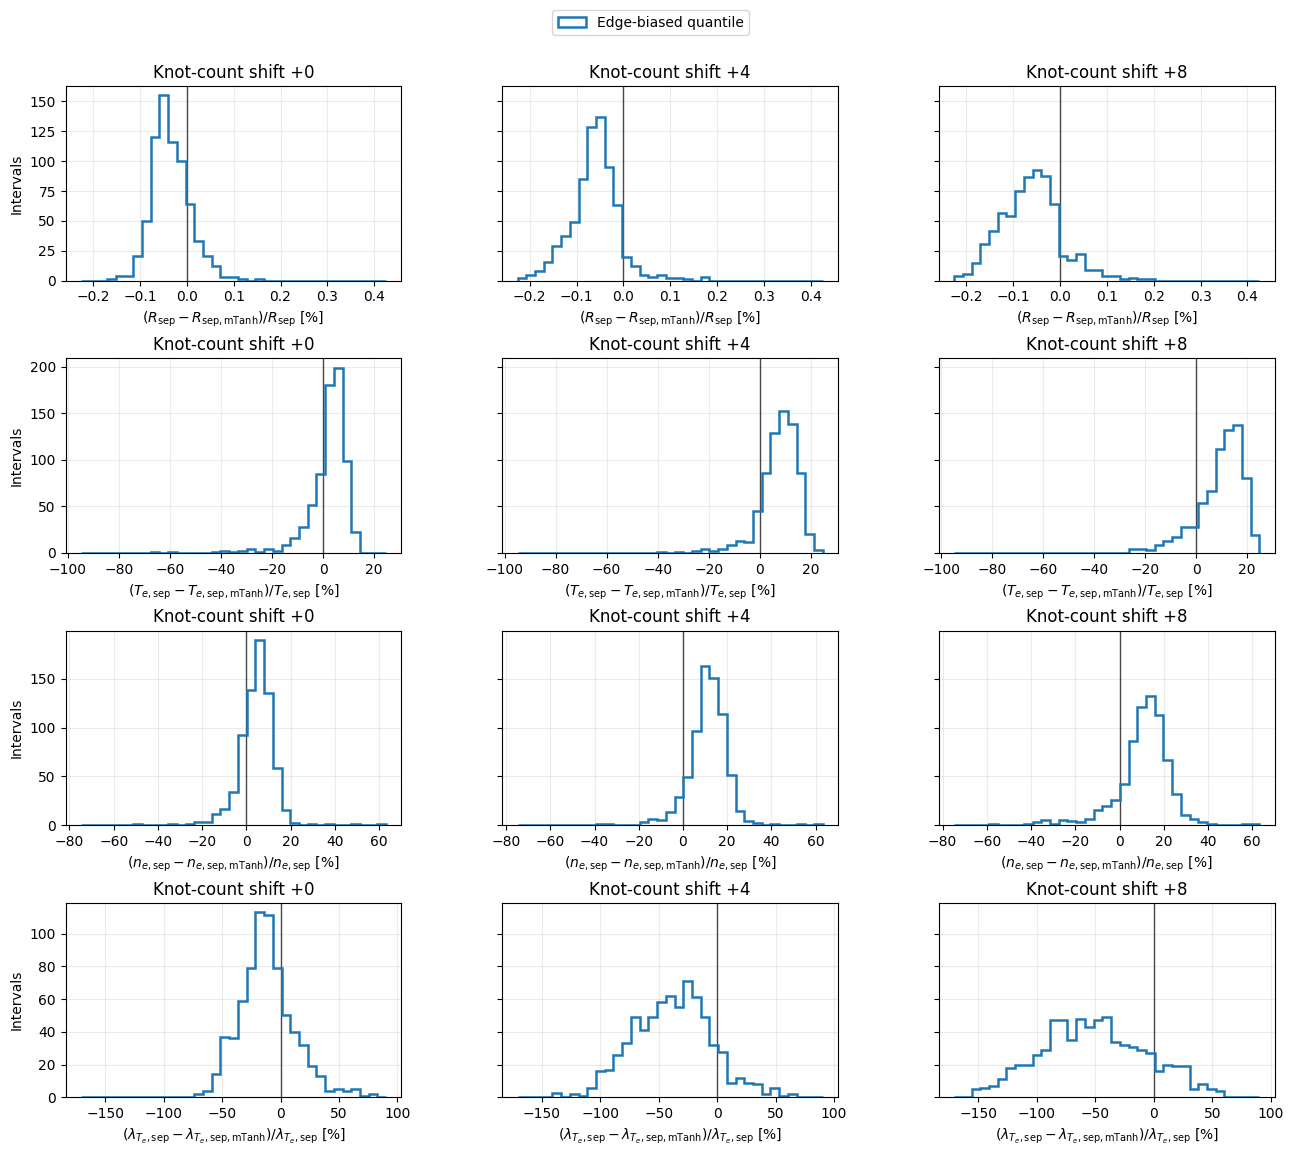

In [39]:
KNOT_SHIFTS_TO_COMPARE = [0,4,8]
QUANTITY_ORDER = ['R_sep', 'Te_sep', 'Ne_sep', 'lambda_Te_sep']
#QUANTITY_ORDER = ['R_sep']
SHIFT_ORDER = list(KNOT_SHIFTS_TO_COMPARE)
STRATEGY_LABELS = {
    'global_quantile': 'Global quantile',
    'balanced_quantile': 'Balanced quantile',
    'hybrid': 'Hybrid',
    'edge_biased_quantile': 'Edge-biased quantile',
}

if comparison_data.empty:
    print('No successful scan rows to plot.')
else:
    fig, axes = plt.subplots(
        len(QUANTITY_ORDER), len(SHIFT_ORDER),
        figsize=(5.2 * len(SHIFT_ORDER), 3.2*len(QUANTITY_ORDER)), sharey='row',
        squeeze=False,
    )
    fig.subplots_adjust(top=0.90, hspace=0.4, wspace=0.3)
    color_map = plt.get_cmap('tab10')
    strategy_colors = {
        strategy: color_map(index)
        for index, strategy in enumerate(STRATEGIES_TO_COMPARE)
    }

    for row_index, quantity in enumerate(QUANTITY_ORDER):
        difference_column = f'{quantity}_difference_pct'
        all_values = comparison_data[difference_column].dropna().to_numpy(float)
        if all_values.size:
            bin_edges = np.histogram_bin_edges(all_values, bins=HIST_BINS)
        else:
            bin_edges = np.linspace(-1.0, 1.0, HIST_BINS + 1)

        for column_index, shift in enumerate(SHIFT_ORDER):
            axis = axes[row_index, column_index]
            shift_rows = comparison_data.loc[
                comparison_data['knot_count_shift'].eq(shift)]
            axis.set_title(f'Knot-count shift {shift:+d}')
            axis.axvline(0.0, color='black', linewidth=1.0, alpha=0.7)
            has_histogram = False
            for strategy in STRATEGIES_TO_COMPARE:
                values = shift_rows.loc[
                    shift_rows['knot_strategy'].eq(strategy),
                    difference_column,
                ].dropna().to_numpy(float)
                if values.size == 0:
                    continue
                axis.hist(
                    values,
                    bins=bin_edges,
                    density=HIST_DENSITY,
                    histtype='step',
                    linewidth=1.8,
                    color=strategy_colors[strategy],
                    label=STRATEGY_LABELS.get(strategy, strategy),
                )
                has_histogram = True
            if not has_histogram:
                axis.text(
                    0.5, 0.5, 'No valid paired values',
                    ha='center', va='center', transform=axis.transAxes,
                )
            axis.set_xlabel(DIFFERENCE_SPECS[quantity]['label'])
            if column_index == 0:
                axis.set_ylabel(
                    'Probability density' if HIST_DENSITY else 'Intervals')

    legend_handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    if legend_handles:
        fig.legend(
            legend_handles, legend_labels,
            loc='upper center', ncol=max(1, len(legend_labels)),
            bbox_to_anchor=(0.5, 0.965),
        )
    #fig.suptitle(
    #    f'Spline minus mTanh relative to spline | {selected_group_label}',
    #    y=0.995,
    #)
    plt.show()

Paired successful intervals: 709 | strategy=edge_biased_quantile | shift=+4 | All shot groups


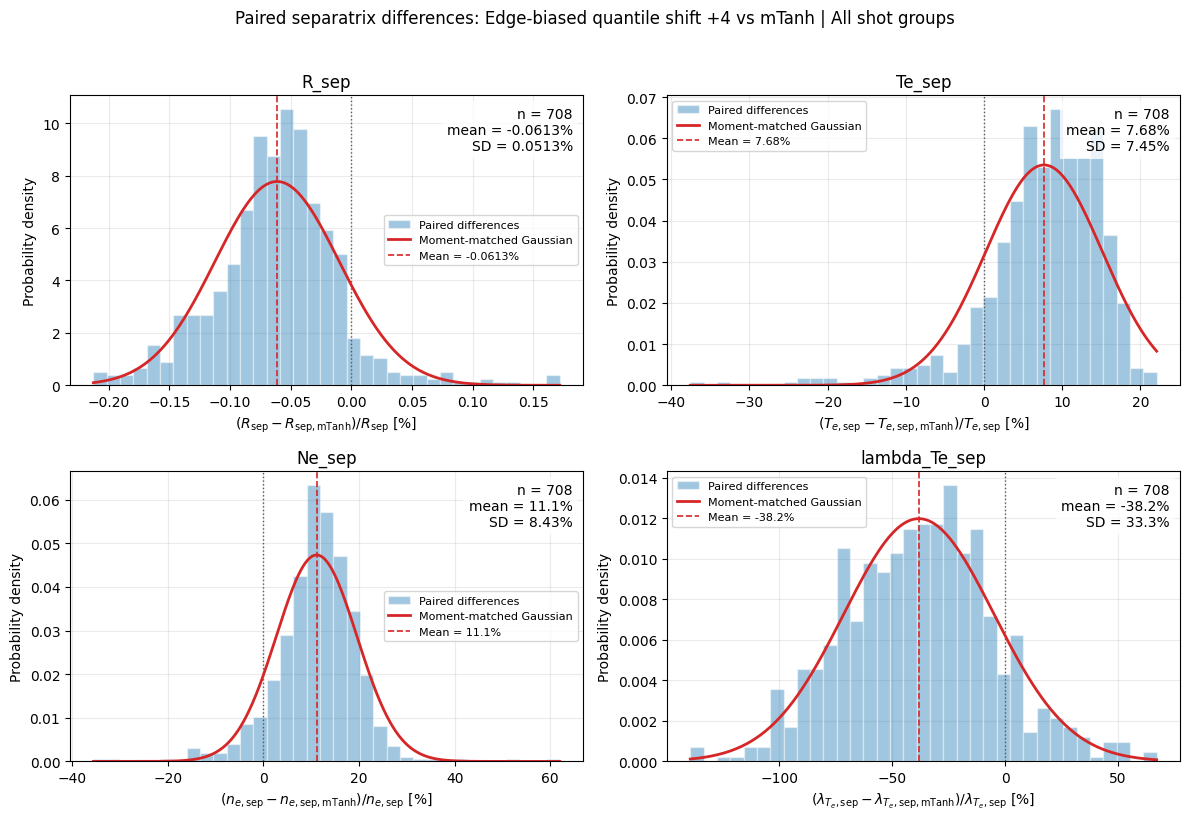

,quantity,n,mean difference (%),SD (%),median (%),Q1 (%),Q3 (%),skewness
0,R_sep,708,-0.061291,0.051310,-0.059308,-0.088627,-0.033836,0.398943
1,Te_sep,708,7.675016,7.453301,8.709340,4.213323,12.716383,-1.585800
2,Ne_sep,708,11.139672,8.433397,11.707087,7.175473,16.292313,-0.378623
3,lambda_Te_sep,708,-38.164935,33.308451,-37.496843,-60.946806,-16.268160,0.082469


Pronounced asymmetry (|skewness| > 1) in: Te_sep. Interpret its Gaussian overlay cautiously; use the median and interquartile range alongside mean and SD.
Differences are 100 * (spline - mTanh) / spline; positive values mean the spline estimate is larger. Gaussian curves are moment-matched descriptive overlays, not a claim that the distributions are normal.


In [41]:
# Paired mTanh vs spline +4 separatrix differences.
if len(STRATEGIES_TO_COMPARE) != 1:
    raise ValueError('Choose exactly one spline strategy for the +4 comparison.')

gaussian_strategy = STRATEGIES_TO_COMPARE[0]
gaussian_shift = 4

gaussian_source = joined.copy()
gaussian_source['fit_success'] = (
    gaussian_source['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
gaussian_source['knot_count_shift'] = pd.to_numeric(
    gaussian_source['knot_count_shift'], errors='coerce')
gaussian_source = gaussian_source.loc[
    gaussian_source['fit_success']
    & gaussian_source['fitted_db_match'].eq('both')
    & gaussian_source['knot_strategy'].eq(gaussian_strategy)
    & gaussian_source['knot_count_shift'].eq(gaussian_shift)
].copy()

if GROUP_PATTERNS:
    gaussian_group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    gaussian_source = gaussian_source.loc[
        gaussian_source['description'].str.contains(
            gaussian_group_regex, case=False, regex=True, na=False)
    ].copy()

if gaussian_source.duplicated(JOIN_KEYS).any():
    raise ValueError('The +4 comparison contains duplicate interval keys.')
if gaussian_source.empty:
    raise ValueError(
        f'No successful, matched intervals found for {gaussian_strategy} shift +4.'
    )

print(
    f'Paired successful intervals: {len(gaussian_source)} | '
    f'strategy={gaussian_strategy} | shift=+4 | {selected_group_label}'
)

gaussian_summary_rows = []
gaussian_values_by_quantity = {}
for gaussian_quantity in QUANTITY_ORDER:
    gaussian_fields = DIFFERENCE_SPECS[gaussian_quantity]
    gaussian_values = spline_relative_percentage_difference(
        gaussian_source[gaussian_fields['mtanh']],
        gaussian_source[gaussian_fields['spline']],
    )
    gaussian_values = gaussian_values[np.isfinite(gaussian_values)]
    gaussian_values_by_quantity[gaussian_quantity] = gaussian_values
    if gaussian_values.size:
        gaussian_summary_rows.append({
            'quantity': gaussian_quantity,
            'n': gaussian_values.size,
            'mean difference (%)': np.mean(gaussian_values),
            'SD (%)': np.std(gaussian_values, ddof=1) if gaussian_values.size > 1 else np.nan,
            'median (%)': np.median(gaussian_values),
            'Q1 (%)': np.percentile(gaussian_values, 25),
            'Q3 (%)': np.percentile(gaussian_values, 75),
            'skewness': pd.Series(gaussian_values).skew(),
        })
    else:
        gaussian_summary_rows.append({
            'quantity': gaussian_quantity,
            'n': 0,
            'mean difference (%)': np.nan,
            'SD (%)': np.nan,
            'median (%)': np.nan,
            'Q1 (%)': np.nan,
            'Q3 (%)': np.nan,
            'skewness': np.nan,
        })

fig, gaussian_axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for gaussian_axis, gaussian_quantity in zip(gaussian_axes.flat, QUANTITY_ORDER):
    gaussian_values = gaussian_values_by_quantity[gaussian_quantity]
    gaussian_axis.axvline(0.0, color='0.35', linewidth=1.0, linestyle=':')
    if gaussian_values.size:
        gaussian_axis.hist(
            gaussian_values,
            bins=HIST_BINS,
            density=True,
            color='tab:blue',
            alpha=0.42,
            edgecolor='white',
            label='Paired differences',
        )
        gaussian_mean = float(np.mean(gaussian_values))
        gaussian_sd = float(np.std(gaussian_values, ddof=1)) if gaussian_values.size > 1 else np.nan
        if gaussian_values.size > 1 and np.isfinite(gaussian_sd) and gaussian_sd > 0.0:
            gaussian_x = np.linspace(gaussian_values.min(), gaussian_values.max(), 400)
            gaussian_pdf = np.exp(
                -0.5 * ((gaussian_x - gaussian_mean) / gaussian_sd) ** 2
            ) / (gaussian_sd * np.sqrt(2.0 * np.pi))
            gaussian_axis.plot(
                gaussian_x, gaussian_pdf,
                color='tab:red', linewidth=2.0,
                label='Moment-matched Gaussian',
            )
        gaussian_axis.axvline(
            gaussian_mean, color='tab:red', linewidth=1.2, linestyle='--',
            label=f'Mean = {gaussian_mean:.3g}%',
        )
        gaussian_axis.text(
            0.98, 0.96,
            f'n = {gaussian_values.size}\nmean = {gaussian_mean:.3g}%\n'
            f'SD = {gaussian_sd:.3g}%' if np.isfinite(gaussian_sd)
            else f'n = {gaussian_values.size}\nmean = {gaussian_mean:.3g}%\nSD = n/a',
            ha='right', va='top', transform=gaussian_axis.transAxes,
            bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'},
        )
    else:
        gaussian_axis.text(
            0.5, 0.5, 'No valid paired values',
            ha='center', va='center', transform=gaussian_axis.transAxes,
        )
    gaussian_axis.set_title(gaussian_quantity)
    gaussian_axis.set_xlabel(DIFFERENCE_SPECS[gaussian_quantity]['label'])
    gaussian_axis.set_ylabel('Probability density')
    gaussian_axis.legend(fontsize=8)

fig.suptitle(
    f'Paired separatrix differences: {strategy_label} shift +4 vs mTanh | '
    f'{selected_group_label}',
    y=1.02,
)
fig.tight_layout()
plt.show()

gaussian_difference_summary = pd.DataFrame(gaussian_summary_rows)
display(gaussian_difference_summary)
strongly_skewed = gaussian_difference_summary.loc[
    gaussian_difference_summary['skewness'].abs().gt(1.0), 'quantity'
].tolist()
if strongly_skewed:
    print(
        'Pronounced asymmetry (|skewness| > 1) in: '
        f'{", ".join(strongly_skewed)}. Interpret its Gaussian overlay cautiously; '
        'use the median and interquartile range alongside mean and SD.'
    )
print(
    'Differences are 100 * (spline - mTanh) / spline; positive values mean '
    'the spline estimate is larger. Gaussian curves are moment-matched '
    'descriptive overlays, not a claim that the distributions are normal.'
)

## 7. Compare Raw Weighted Chi-Squared Distributions

The mTanh weighted-$\\chi^2$ values come from the fitted database, and spline values come from successful scan rows matched to the fitted database. Te and Ne distributions use the same bins and shot-group filter.

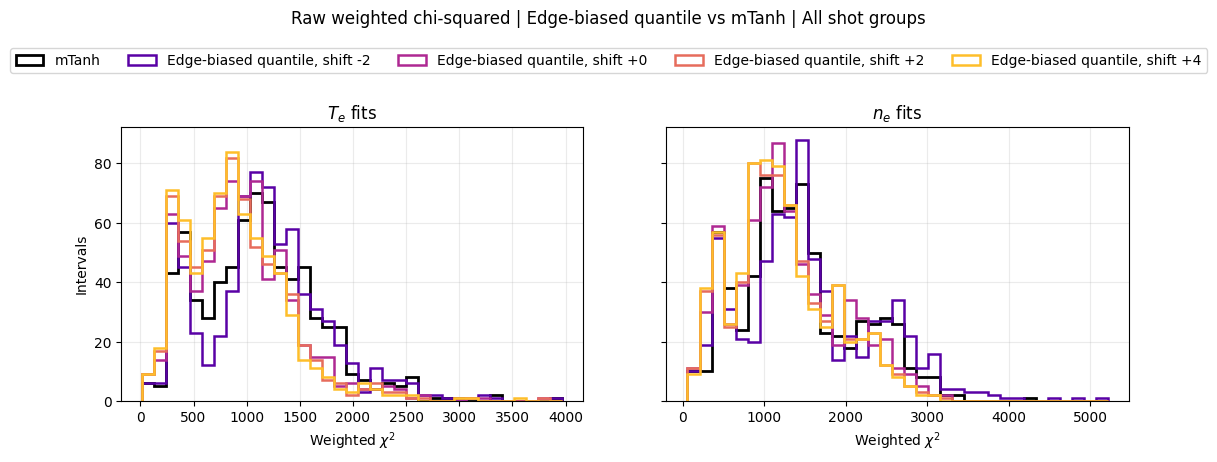

In [25]:
KNOT_SHIFTS_TO_COMPARE = [-2, 0, 2, 4]
SHIFT_ORDER = list(KNOT_SHIFTS_TO_COMPARE)
if len(STRATEGIES_TO_COMPARE) != 1:
    raise ValueError('Choose exactly one spline strategy for the chi-squared histogram.')
strategy_to_compare = STRATEGIES_TO_COMPARE[0]
strategy_label = STRATEGY_LABELS.get(strategy_to_compare, strategy_to_compare)

chi2_plot_scan = scan_raw.copy()
chi2_plot_scan['shot_id'] = pd.to_numeric(
    chi2_plot_scan['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    chi2_plot_scan[time_column] = pd.to_numeric(
        chi2_plot_scan[time_column], errors='coerce').round(9)
chi2_plot_scan['fit_success'] = (
    chi2_plot_scan['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
if GROUP_PATTERNS:
    chi2_plot_scan = chi2_plot_scan.merge(
        shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id'),
        on='shot_id',
        how='left',
        validate='many_to_one',
    )
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    chi2_plot_scan = chi2_plot_scan.loc[
        chi2_plot_scan['description'].str.contains(
            group_regex, case=False, regex=True, na=False)
    ].copy()
chi2_plot_scan = chi2_plot_scan.loc[
    chi2_plot_scan['fit_success']
    & chi2_plot_scan['knot_strategy'].eq(strategy_to_compare)
    & chi2_plot_scan['knot_count_shift'].isin(SHIFT_ORDER)
].copy()

chi2_baseline = fitted_raw.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).copy()
chi2_baseline['shot_id'] = pd.to_numeric(
    chi2_baseline['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    chi2_baseline[time_column] = pd.to_numeric(
        chi2_baseline[time_column], errors='coerce').round(9)
chi2_baseline_columns = JOIN_KEYS + [
    'mtanh_Te_weighted_sse', 'mtanh_Ne_weighted_sse',
]
missing_chi2_columns = sorted(
    set(chi2_baseline_columns).difference(chi2_baseline.columns)
    | {'Te_chi_squared', 'Ne_chi_squared'}.difference(chi2_plot_scan.columns)
)
if missing_chi2_columns:
    raise ValueError(f'Missing weighted chi-squared columns: {missing_chi2_columns}')
chi2_baseline = chi2_baseline.loc[:, chi2_baseline_columns]
if chi2_baseline.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted database has duplicate interval keys.')
chi2_plot_data = chi2_plot_scan.merge(
    chi2_baseline,
    on=JOIN_KEYS,
    how='inner',
    validate='many_to_one',
)

CHI_SQUARED_SPECS = {
    'Te': {
        'mtanh': 'mtanh_Te_weighted_sse',
        'spline': 'Te_chi_squared',
        'title': r'$T_e$ fits',
    },
    'Ne': {
        'mtanh': 'mtanh_Ne_weighted_sse',
        'spline': 'Ne_chi_squared',
        'title': r'$n_e$ fits',
    },
}
shift_color_map = plt.get_cmap('plasma')
shift_positions = np.linspace(0.16, 0.86, len(SHIFT_ORDER))
shift_colors = {
    shift: shift_color_map(position)
    for shift, position in zip(SHIFT_ORDER, shift_positions)
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
fig.subplots_adjust(top=0.72, wspace=0.18)

for axis, (quantity, fields) in zip(axes, CHI_SQUARED_SPECS.items()):
    distributions = []
    baseline_values = pd.to_numeric(
        chi2_plot_data[fields['mtanh']], errors='coerce').to_numpy(float)
    baseline_values = baseline_values[np.isfinite(baseline_values) & (baseline_values >= 0.0)]
    baseline_values = chi2_plot_data.loc[:, JOIN_KEYS].assign(
        chi2=baseline_values
    ).drop_duplicates(JOIN_KEYS)['chi2'].to_numpy(float)
    if baseline_values.size:
        distributions.append(baseline_values)

    spline_values_by_shift = {}
    for shift in SHIFT_ORDER:
        spline_values = pd.to_numeric(
            chi2_plot_data.loc[
                chi2_plot_data['knot_count_shift'].eq(shift),
                fields['spline'],
            ],
            errors='coerce',
        ).to_numpy(float)
        spline_values = spline_values[np.isfinite(spline_values) & (spline_values >= 0.0)]
        if spline_values.size:
            spline_values_by_shift[shift] = spline_values
            distributions.append(spline_values)

    combined_values = (
        np.concatenate(distributions) if distributions else np.array([]))
    bin_edges = (
        np.histogram_bin_edges(combined_values, bins=HIST_BINS)
        if combined_values.size else np.linspace(0.0, 1.0, HIST_BINS + 1)
    )
    if baseline_values.size:
        axis.hist(
            baseline_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=2.0,
            color='black',
            label='mTanh',
        )
    for shift, spline_values in spline_values_by_shift.items():
        axis.hist(
            spline_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=1.8,
            color=shift_colors[shift],
            label=f'{strategy_label}, shift {shift:+d}',
        )
    axis.set_title(fields['title'])
    axis.set_xlabel(r'Weighted $\chi^2$')
    if not distributions:
        axis.text(0.5, 0.5, 'No valid chi-squared values',
                  ha='center', va='center', transform=axis.transAxes)

axes[0].set_ylabel(
    'Probability density' if HIST_DENSITY else 'Intervals')
handles = []
labels = []
for axis in axes:
    current_handles, current_labels = axis.get_legend_handles_labels()
    for handle, label in zip(current_handles, current_labels):
        if label not in labels:
            handles.append(handle)
            labels.append(label)
if handles:
    fig.legend(
        handles, labels, loc='upper center',
        ncol=1 + len(SHIFT_ORDER), bbox_to_anchor=(0.5, 0.91),
    )
fig.suptitle(
    f'Raw weighted chi-squared | {strategy_label} vs mTanh | {selected_group_label}',
    y=0.98,
)
plt.show()

Fitted database CSV: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_05_new_outlier_rule/34383---38808_database_dt-0.1s_fitted.csv
Successful selected spline variants: 4255
Unmatched raw scan rows: 0
Unmatched fitted CSV intervals: 0


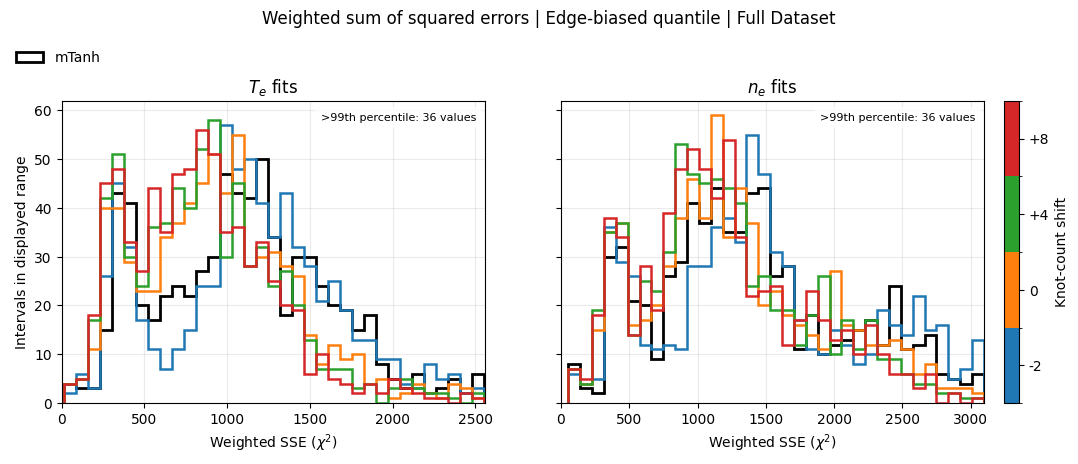

Each x-axis is capped at the pooled 99th percentile for that quantity. Values above the limit are omitted from the displayed bins only; the source data are unchanged.


,quantity,fit model,values above display limit
0,Te,mTanh,9
1,Te,"Edge-biased quantile, shift -2",14
2,Te,"Edge-biased quantile, shift +0",6
3,Te,"Edge-biased quantile, shift +4",4
4,Te,"Edge-biased quantile, shift +8",3
5,Ne,mTanh,7
6,Ne,"Edge-biased quantile, shift -2",24
7,Ne,"Edge-biased quantile, shift +0",2
8,Ne,"Edge-biased quantile, shift +4",1
9,Ne,"Edge-biased quantile, shift +8",2


In [36]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap

HIST_BINS = 35
HISTOGRAM_UPPER_PERCENTILE = 99.0
KNOT_SHIFTS_TO_COMPARE = [-2, 0, 4, 8]
QUANTITY_ORDER = ['R_sep', 'Te_sep', 'Ne_sep', 'lambda_Te_sep']
#QUANTITY_ORDER = ['R_sep']
SHIFT_ORDER = list(KNOT_SHIFTS_TO_COMPARE)
if len(STRATEGIES_TO_COMPARE) != 1:
    raise ValueError('Choose exactly one spline strategy for chi-squared comparisons.')
strategy_to_compare = STRATEGIES_TO_COMPARE[0]
strategy_label = STRATEGY_LABELS.get(strategy_to_compare, strategy_to_compare)

RAW_SSE_SPECS = {
    'Te': {
        'mtanh': 'mtanh_Te_weighted_sse',
        'spline': 'Te_chi_squared',
        'title': r'$T_e$ fits',
    },
    'Ne': {
        'mtanh': 'mtanh_Ne_weighted_sse',
        'spline': 'Ne_chi_squared',
        'title': r'$n_e$ fits',
    },
}

fitted_csv_path = FITTED_DATABASE_PATH.with_suffix('.csv')
if not fitted_csv_path.is_file():
    raise FileNotFoundError(f'Fitted database CSV not found: {fitted_csv_path}')

raw_fitted_csv = pd.read_csv(fitted_csv_path).rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
})
raw_variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
raw_fit_columns = [fields['mtanh'] for fields in RAW_SSE_SPECS.values()]
raw_spline_columns = [fields['spline'] for fields in RAW_SSE_SPECS.values()]
missing_raw_fields = sorted(
    set(JOIN_KEYS + raw_fit_columns).difference(raw_fitted_csv.columns)
    | set(raw_variant_keys + raw_spline_columns).difference(scan_raw.columns)
)
if missing_raw_fields:
    raise ValueError(f'Missing unreduced chi-squared fields: {missing_raw_fields}')

raw_mtanh = raw_fitted_csv.loc[:, JOIN_KEYS + raw_fit_columns].copy()
raw_spline = scan_raw.loc[:, raw_variant_keys + raw_spline_columns].copy()
for frame in (raw_mtanh, raw_spline):
    frame['shot_id'] = pd.to_numeric(frame['shot_id'], errors='raise').astype(int)
    for time_column in ('t_begin', 't_end'):
        frame[time_column] = pd.to_numeric(
            frame[time_column], errors='coerce').round(9)

if raw_mtanh.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted CSV has duplicate shot-interval keys.')
if raw_spline.duplicated(raw_variant_keys).any():
    raise ValueError('The scan CSV has duplicate strategy/shift interval keys.')

raw_sse_data = comparison_data.merge(
    raw_spline,
    on=raw_variant_keys,
    how='left',
    validate='one_to_one',
    indicator='_raw_scan_match',
).merge(
    raw_mtanh,
    on=JOIN_KEYS,
    how='left',
    validate='many_to_one',
    indicator='_raw_db_match',
)
print(f'Fitted database CSV: {fitted_csv_path}')
print(f'Successful selected spline variants: {len(raw_sse_data)}')
print('Unmatched raw scan rows:', int(raw_sse_data['_raw_scan_match'].ne('both').sum()))
print('Unmatched fitted CSV intervals:', int(raw_sse_data['_raw_db_match'].ne('both').sum()))

raw_mtanh_baseline = (
    raw_sse_data.loc[:, JOIN_KEYS + raw_fit_columns]
    .drop_duplicates(JOIN_KEYS)
)
shift_color_map = ListedColormap(
    plt.get_cmap('tab10').colors[:len(SHIFT_ORDER)],
    name='tab10_knot_shifts',
)
shift_boundaries = np.arange(len(SHIFT_ORDER) + 1) - 0.5
shift_norm = BoundaryNorm(shift_boundaries, shift_color_map.N)
shift_colors = {
    shift: shift_color_map(index)
    for index, shift in enumerate(SHIFT_ORDER)
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
fig.subplots_adjust(top=0.80, bottom=0.17, right=0.88, wspace=0.18)
overflow_rows = []

for axis, (quantity, fields) in zip(axes, RAW_SSE_SPECS.items()):
    mtanh_values = pd.to_numeric(
        raw_mtanh_baseline[fields['mtanh']], errors='coerce').to_numpy(float)
    mtanh_values = mtanh_values[np.isfinite(mtanh_values) & (mtanh_values >= 0.0)]

    spline_values_by_shift = {}
    distributions = [mtanh_values] if mtanh_values.size else []
    for shift in SHIFT_ORDER:
        spline_values = pd.to_numeric(
            raw_sse_data.loc[
                raw_sse_data['knot_strategy'].eq(strategy_to_compare)
                & raw_sse_data['knot_count_shift'].eq(shift),
                fields['spline'],
            ],
            errors='coerce',
        ).to_numpy(float)
        spline_values = spline_values[
            np.isfinite(spline_values) & (spline_values >= 0.0)]
        if spline_values.size:
            spline_values_by_shift[shift] = spline_values
            distributions.append(spline_values)

    combined_values = (
        np.concatenate(distributions) if distributions else np.array([]))
    if combined_values.size:
        display_max = float(np.percentile(
            combined_values, HISTOGRAM_UPPER_PERCENTILE))
        in_range_values = combined_values[combined_values <= display_max]
        bin_edges = np.histogram_bin_edges(in_range_values, bins=HIST_BINS)
    else:
        display_max = 1.0
        bin_edges = np.linspace(0.0, display_max, HIST_BINS + 1)

    overflow_rows.append({
        'quantity': quantity,
        'fit model': 'mTanh',
        'values above display limit': int(np.count_nonzero(mtanh_values > display_max)),
    })
    if mtanh_values.size:
        axis.hist(
            mtanh_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=2.0,
            color='black',
            label='mTanh',
        )

    for shift, spline_values in spline_values_by_shift.items():
        overflow_rows.append({
            'quantity': quantity,
            'fit model': f'{strategy_label}, shift {shift:+d}',
            'values above display limit': int(np.count_nonzero(spline_values > display_max)),
        })
        axis.hist(
            spline_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=1.8,
            color=shift_colors[shift],
        )

    axis.set_xlim(0.0, display_max)
    axis.set_title(fields['title'])
    axis.set_xlabel(r'Weighted SSE ($\chi^2$)')
    overflow_total = sum(
        row['values above display limit']
        for row in overflow_rows if row['quantity'] == quantity
    )
    axis.text(
        0.98, 0.96,
        f'>{HISTOGRAM_UPPER_PERCENTILE:.0f}th percentile: {overflow_total} values',
        ha='right', va='top', transform=axis.transAxes, fontsize=8,
        bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'},
    )

axes[0].set_ylabel(
    'Probability density in displayed range'
    if HIST_DENSITY else 'Intervals in displayed range'
)
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles, labels, loc='upper left',
        bbox_to_anchor=(0.08, 0.93), frameon=False,
    )
shift_colorbar = fig.colorbar(
    ScalarMappable(norm=shift_norm, cmap=shift_color_map),
    ax=axes,
    pad=0.02,
    fraction=0.04,
    boundaries=shift_boundaries,
    ticks=np.arange(len(SHIFT_ORDER)),
)
shift_colorbar.set_label('Knot-count shift')
shift_colorbar.ax.set_yticklabels([
    '0' if shift == 0 else f'{shift:+d}'
    for shift in SHIFT_ORDER
])
fig.suptitle(
    f'Weighted sum of squared errors | {strategy_label} | Full Dataset',
    y=0.99,
)
plt.show()

print(
    f'Each x-axis is capped at the pooled {HISTOGRAM_UPPER_PERCENTILE:.0f}th '
    'percentile for that quantity. Values above the limit are omitted from the '
    'displayed bins only; the source data are unchanged.'
)
display(pd.DataFrame(overflow_rows))

In [37]:
THESIS_FIGURE_PATH = (
    PROJECT_ROOT.parent
    / 'TESE_Joao_Pedro_Nunes'
    / 'chapters'
    / 'Formulation_and_Methods'
    / 'Comparison_Fit_Methods'
    / 'figures'
    / 'weighted_chi_squared_knot_shift_histograms.pdf'
)
if not THESIS_FIGURE_PATH.parent.is_dir():
    raise FileNotFoundError(f'Thesis figure directory not found: {THESIS_FIGURE_PATH.parent}')
fig.savefig(THESIS_FIGURE_PATH, format='pdf', bbox_inches='tight')
print(f'Saved figure: {THESIS_FIGURE_PATH}')

Saved figure: /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Comparison_Fit_Methods/figures/weighted_chi_squared_knot_shift_histograms.pdf


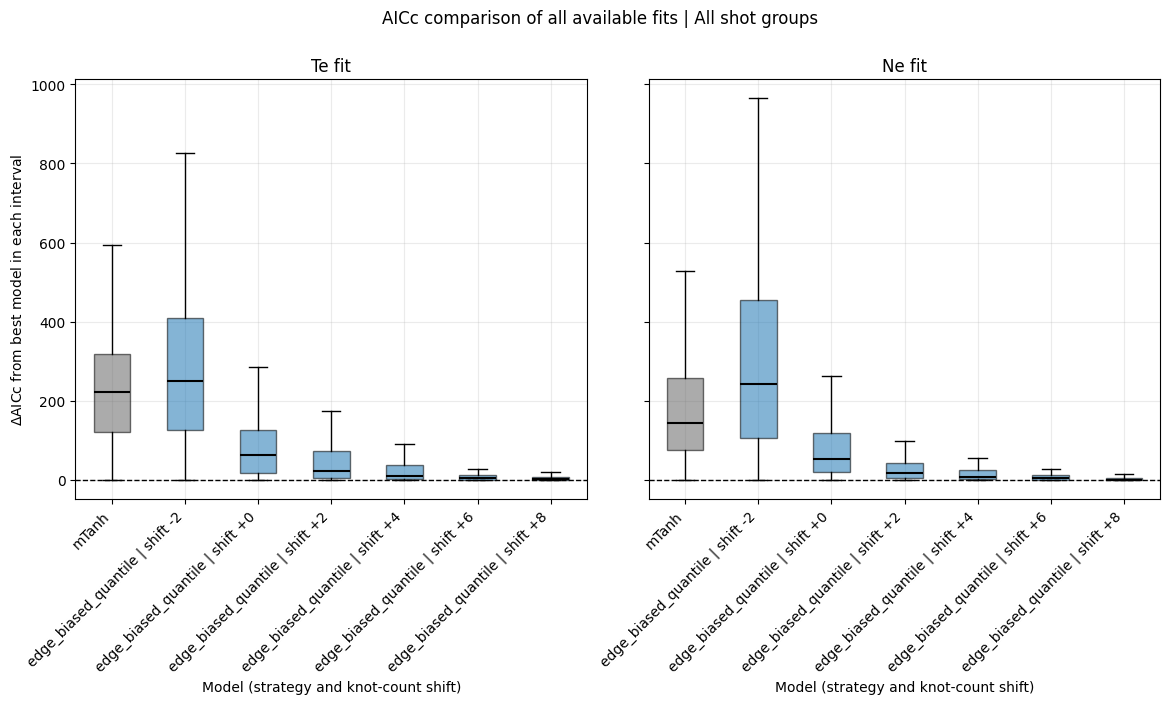

,quantity,model,intervals,median_delta_from_best,fraction_best,median_rank
13,Ne,edge_biased_quantile | shift +8,708,1.232231,0.454802,2.0
12,Ne,edge_biased_quantile | shift +6,708,5.197493,0.220339,2.0
11,Ne,edge_biased_quantile | shift +4,709,8.588683,0.146685,3.0
10,Ne,edge_biased_quantile | shift +2,710,18.596006,0.076056,4.0
9,Ne,edge_biased_quantile | shift +0,710,54.062036,0.070423,5.0
7,Ne,mTanh,710,144.165232,0.023944,6.0
8,Ne,edge_biased_quantile | shift -2,710,243.421013,0.009859,7.0
6,Te,edge_biased_quantile | shift +8,708,1.846312,0.429379,2.0
5,Te,edge_biased_quantile | shift +6,708,5.947811,0.237288,2.0
4,Te,edge_biased_quantile | shift +4,709,10.572266,0.136812,3.0


Each model is compared with the lowest-AICc model for the same interval and quantity.
Delta 0 means best (or tied); larger values mean less support relative to that interval's best fit.
AICc uses nominal coefficient counts; constrained-spline effective degrees of freedom may differ.


In [10]:
import json

variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
parameter_columns = ['Te_spline_parameters', 'Ne_spline_parameters']
required_scan_columns = set(
    variant_keys + parameter_columns + [
        'fit_success', 'Te_chi_squared', 'Ne_chi_squared',
    ]
)
missing_scan_columns = sorted(required_scan_columns.difference(scan_raw.columns))
if missing_scan_columns:
    raise ValueError(f'Scan CSV is missing AICc inputs: {missing_scan_columns}')

all_scan_variants = scan_raw.copy()
all_scan_variants['shot_id'] = pd.to_numeric(
    all_scan_variants['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    all_scan_variants[time_column] = pd.to_numeric(
        all_scan_variants[time_column], errors='coerce').round(9)
all_scan_variants['knot_count_shift'] = pd.to_numeric(
    all_scan_variants['knot_count_shift'], errors='raise').astype(int)
all_scan_variants['fit_success'] = (
    all_scan_variants['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
all_scan_variants = all_scan_variants.merge(
    shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id'),
    on='shot_id',
    how='left',
    validate='many_to_one',
)
all_scan_variants['description'] = all_scan_variants['description'].fillna('Unclassified')
if GROUP_PATTERNS:
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    group_mask = all_scan_variants['description'].str.contains(
        group_regex, case=False, regex=True, na=False)
    all_scan_variants = all_scan_variants.loc[group_mask].copy()
all_scan_variants = all_scan_variants.loc[all_scan_variants['fit_success']].copy()
if all_scan_variants.duplicated(variant_keys).any():
    raise ValueError('The scan CSV contains duplicate interval/model combinations.')

fitted_for_aic = raw_fitted_csv.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
})
baseline_columns = JOIN_KEYS + [
    'n_points', 'mtanh_Te_weighted_sse', 'mtanh_Ne_weighted_sse',
]
missing_baseline_columns = sorted(
    set(baseline_columns).difference(fitted_for_aic.columns)
)
if missing_baseline_columns:
    raise ValueError(f'Fitted CSV is missing AICc inputs: {missing_baseline_columns}')
mtanh_baseline = fitted_for_aic.loc[:, baseline_columns].copy()
mtanh_baseline['shot_id'] = pd.to_numeric(
    mtanh_baseline['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    mtanh_baseline[time_column] = pd.to_numeric(
        mtanh_baseline[time_column], errors='coerce').round(9)
if mtanh_baseline.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted CSV has duplicate mTanh interval keys.')

all_aic_data = all_scan_variants.merge(
    mtanh_baseline,
    on=JOIN_KEYS,
    how='inner',
    validate='many_to_one',
)


def stored_parameter_count(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return len(value)
    if not isinstance(value, str) or not value.strip():
        return np.nan
    try:
        return len(json.loads(value))
    except (TypeError, ValueError):
        return np.nan


def configured_mtanh_parameter_count(quantity):
    quantity_config = (
        pipeline_config.get('fit_config', {})
        .get('fits', {})
        .get('mtanh', {})
        .get(quantity, {})
    )
    fixed_count = sum(
        quantity_config.get(name) is not None
        for name in ('fix_x0', 'fix_w', 'fix_a_tail')
    )
    return (
        2
        + int(quantity_config.get('deg_tail', 3)) + 1
        + int(quantity_config.get('deg_top', 3)) + 1
        - fixed_count
    )


def corrected_aic(chi_squared, parameter_count, n_points):
    chi_squared = pd.to_numeric(chi_squared, errors='coerce').to_numpy(float)
    parameter_count = pd.to_numeric(parameter_count, errors='coerce').to_numpy(float)
    n_points = pd.to_numeric(n_points, errors='coerce').to_numpy(float)
    values = np.full(chi_squared.shape, np.nan, dtype=float)
    valid = (
        np.isfinite(chi_squared)
        & np.isfinite(parameter_count)
        & np.isfinite(n_points)
        & (n_points > parameter_count + 1)
    )
    values[valid] = (
        chi_squared[valid]
        + 2.0 * parameter_count[valid]
        + 2.0 * parameter_count[valid] * (parameter_count[valid] + 1.0)
        / (n_points[valid] - parameter_count[valid] - 1.0)
    )
    return values


for quantity, parameter_column in (
    ('Te', 'Te_spline_parameters'),
    ('Ne', 'Ne_spline_parameters'),
):
    spline_count = all_aic_data[parameter_column].map(stored_parameter_count)
    mtanh_count = configured_mtanh_parameter_count(quantity)
    all_aic_data[f'{quantity}_spline_AICc'] = corrected_aic(
        all_aic_data[f'{quantity}_chi_squared'],
        spline_count,
        all_aic_data['n_points'],
    )
    all_aic_data[f'{quantity}_mtanh_AICc'] = corrected_aic(
        all_aic_data[f'mtanh_{quantity}_weighted_sse'],
        pd.Series(mtanh_count, index=all_aic_data.index),
        all_aic_data['n_points'],
    )

model_rows = []
for quantity in ('Te', 'Ne'):
    spline_models = all_aic_data.loc[:, JOIN_KEYS + [
        'knot_strategy', 'knot_count_shift', f'{quantity}_spline_AICc',
    ]].copy()
    spline_models['model'] = (
        spline_models['knot_strategy'].astype(str)
        + ' | shift '
        + spline_models['knot_count_shift'].map(lambda shift: f'{shift:+d}')
    )
    spline_models['AICc'] = spline_models.pop(f'{quantity}_spline_AICc')
    spline_models['quantity'] = quantity
    model_rows.append(spline_models.loc[:, JOIN_KEYS + ['quantity', 'model', 'AICc']])

    mtanh_models = all_aic_data.loc[:, JOIN_KEYS + [f'{quantity}_mtanh_AICc']].copy()
    mtanh_models = mtanh_models.drop_duplicates(JOIN_KEYS)
    mtanh_models['model'] = 'mTanh'
    mtanh_models['AICc'] = mtanh_models.pop(f'{quantity}_mtanh_AICc')
    mtanh_models['quantity'] = quantity
    model_rows.append(mtanh_models.loc[:, JOIN_KEYS + ['quantity', 'model', 'AICc']])

model_aic = pd.concat(model_rows, ignore_index=True).dropna(subset=['AICc'])
model_group_keys = ['quantity'] + JOIN_KEYS
model_aic['best_AICc'] = model_aic.groupby(model_group_keys)['AICc'].transform('min')
model_aic['delta_from_best'] = model_aic['AICc'] - model_aic['best_AICc']
model_aic['rank'] = model_aic.groupby(model_group_keys)['AICc'].rank(method='min')

variants = (
    all_aic_data[['knot_strategy', 'knot_count_shift']]
    .drop_duplicates()
    .sort_values(['knot_strategy', 'knot_count_shift'])
)
model_order = ['mTanh'] + [
    f'{row.knot_strategy} | shift {int(row.knot_count_shift):+d}'
    for row in variants.itertuples(index=False)
]
strategy_names = variants['knot_strategy'].astype(str).unique().tolist()
strategy_cmap = plt.get_cmap('tab10')
strategy_colors = {
    strategy: strategy_cmap(index % 10)
    for index, strategy in enumerate(strategy_names)
}
model_colors = {'mTanh': '0.4'}
for row in variants.itertuples(index=False):
    model_colors[f'{row.knot_strategy} | shift {int(row.knot_count_shift):+d}'] = (
        strategy_colors[str(row.knot_strategy)]
    )

summary_rows = []
figure_width = max(14.0, 0.52 * len(model_order))
fig, axes = plt.subplots(1, 2, figsize=(figure_width, 7), sharey=True)
fig.subplots_adjust(top=0.88, bottom=0.28, wspace=0.12)
for axis, quantity in zip(axes, ('Te', 'Ne')):
    distributions = []
    plotted_models = []
    for model in model_order:
        selected = model_aic.loc[
            model_aic['quantity'].eq(quantity) & model_aic['model'].eq(model)
        ]
        deltas = selected['delta_from_best'].to_numpy(float)
        ranks = selected['rank'].to_numpy(float)
        summary_rows.append({
            'quantity': quantity,
            'model': model,
            'intervals': deltas.size,
            'median_delta_from_best': np.median(deltas) if deltas.size else np.nan,
            'fraction_best': np.mean(np.isclose(deltas, 0.0)) if deltas.size else np.nan,
            'median_rank': np.median(ranks) if ranks.size else np.nan,
        })
        if deltas.size:
            distributions.append(deltas)
            plotted_models.append(model)

    if distributions:
        boxplot = axis.boxplot(
            distributions,
            patch_artist=True,
            showfliers=False,
            medianprops={'color': 'black', 'linewidth': 1.5},
        )
        for patch, model in zip(boxplot['boxes'], plotted_models):
            patch.set_facecolor(model_colors[model])
            patch.set_alpha(0.55)
        axis.set_xticks(np.arange(1, len(plotted_models) + 1))
        axis.set_xticklabels(plotted_models, rotation=45, ha='right')
    else:
        axis.text(
            0.5, 0.5, 'No valid AICc comparisons',
            ha='center', va='center', transform=axis.transAxes,
        )
    axis.axhline(0.0, color='black', linewidth=1.0, linestyle='--')
    axis.set_title(f'{quantity} fit')
    axis.set_xlabel('Model (strategy and knot-count shift)')

axes[0].set_ylabel(r'$\Delta\mathrm{AICc}$ from best model in each interval')
fig.suptitle(
    f'AICc comparison of all available fits | {selected_group_label}',
    y=0.98,
)
plt.show()

model_aic_summary = pd.DataFrame(summary_rows).sort_values(
    ['quantity', 'median_rank', 'median_delta_from_best'], na_position='last'
)
display(model_aic_summary)
print('Each model is compared with the lowest-AICc model for the same interval and quantity.')
print('Delta 0 means best (or tied); larger values mean less support relative to that interval\'s best fit.')
print('AICc uses nominal coefficient counts; constrained-spline effective degrees of freedom may differ.')

In [26]:
latest_scan_summary = scan_raw.copy()
latest_scan_summary['shot_id'] = pd.to_numeric(
    latest_scan_summary['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    latest_scan_summary[time_column] = pd.to_numeric(
        latest_scan_summary[time_column], errors='coerce').round(9)
latest_scan_summary['fit_success'] = (
    latest_scan_summary['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
latest_scan_summary = latest_scan_summary.merge(
    shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id'),
    on='shot_id',
    how='left',
    validate='many_to_one',
)
latest_scan_summary['description'] = latest_scan_summary['description'].fillna('Unclassified')
if GROUP_PATTERNS:
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    latest_scan_summary = latest_scan_summary.loc[
        latest_scan_summary['description'].str.contains(
            group_regex, case=False, regex=True, na=False)
    ].copy()
if latest_scan_summary.empty:
    raise ValueError('No rows from the latest scan match the selected shot group.')

latest_point_counts = raw_fitted_csv.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).loc[:, JOIN_KEYS + ['n_points']].copy()
latest_point_counts['shot_id'] = pd.to_numeric(
    latest_point_counts['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    latest_point_counts[time_column] = pd.to_numeric(
        latest_point_counts[time_column], errors='coerce').round(9)
latest_point_counts['n_points'] = pd.to_numeric(
    latest_point_counts['n_points'], errors='coerce')
if latest_point_counts.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted CSV has duplicate interval keys for n_points.')
latest_scan_summary = latest_scan_summary.merge(
    latest_point_counts,
    on=JOIN_KEYS,
    how='left',
    validate='many_to_one',
)

latest_scan_summary['_interval_key'] = list(map(
    tuple, latest_scan_summary.loc[:, JOIN_KEYS].to_numpy()))
latest_variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
if latest_scan_summary.duplicated(latest_variant_keys).any():
    raise ValueError('The latest scan contains duplicate interval/model combinations.')
total_latest_intervals = latest_scan_summary['_interval_key'].nunique()
latest_success_summary = (
    latest_scan_summary.groupby(
        ['knot_strategy', 'knot_count_shift'], dropna=False)
    .agg(
        attempted_intervals=('_interval_key', 'nunique'),
        successful_intervals=('fit_success', 'sum'),
        actual_knot_counts=('n_knots', lambda values: sorted(
            pd.to_numeric(values, errors='coerce').dropna().astype(int).unique()
        )),
    )
    .reset_index()
)
latest_success_summary['total_intervals'] = total_latest_intervals
latest_success_summary['failed_intervals'] = (
    latest_success_summary['attempted_intervals']
    - latest_success_summary['successful_intervals']
)
latest_success_summary['success_rate_pct'] = (
    100.0 * latest_success_summary['successful_intervals']
    / latest_success_summary['total_intervals']
)
print(f'Latest scan: {SCAN_CSV_PATH.name}')
print(f'Distinct intervals in selected group: {total_latest_intervals}')
display(latest_success_summary)

latest_fit_baseline = fitted_raw.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).copy()
latest_fit_baseline['shot_id'] = pd.to_numeric(
    latest_fit_baseline['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    latest_fit_baseline[time_column] = pd.to_numeric(
        latest_fit_baseline[time_column], errors='coerce').round(9)
chi2_baseline_columns = JOIN_KEYS + [
    'mtanh_Te_weighted_sse', 'mtanh_Ne_weighted_sse',
]
missing_chi2_baseline = sorted(
    set(chi2_baseline_columns).difference(latest_fit_baseline.columns)
)
if missing_chi2_baseline:
    raise ValueError(f'Fitted database is missing weighted-chi-squared fields: {missing_chi2_baseline}')
latest_fit_baseline = latest_fit_baseline.loc[:, chi2_baseline_columns]
if latest_fit_baseline.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted database has duplicate interval keys.')
latest_fit_baseline = latest_fit_baseline.merge(
    latest_point_counts,
    on=JOIN_KEYS,
    how='left',
    validate='one_to_one',
)
latest_fit_baseline['_interval_key'] = list(map(
    tuple, latest_fit_baseline.loc[:, JOIN_KEYS].to_numpy()))
scan_interval_keys = set(latest_scan_summary['_interval_key'])
mtanh_results = latest_fit_baseline.loc[
    latest_fit_baseline['_interval_key'].isin(scan_interval_keys)
].copy()
mtanh_te = pd.to_numeric(
    mtanh_results['mtanh_Te_weighted_sse'], errors='coerce').to_numpy(float)
mtanh_ne = pd.to_numeric(
    mtanh_results['mtanh_Ne_weighted_sse'], errors='coerce').to_numpy(float)
mtanh_successful_intervals = mtanh_results.loc[
    np.isfinite(mtanh_te) & np.isfinite(mtanh_ne), '_interval_key'
].nunique()

model_stats = {
    'mTanh': {
        'model': 'mTanh',
        'successful intervals': mtanh_successful_intervals,
        'tried intervals': total_latest_intervals,
    }
}
for quantity in ('Te', 'Ne'):
    raw_values = pd.to_numeric(
        mtanh_results[f'mtanh_{quantity}_weighted_sse'], errors='coerce'
    ).to_numpy(float)
    point_counts = pd.to_numeric(
        mtanh_results['n_points'], errors='coerce').to_numpy(float)
    valid_values = (
        np.isfinite(raw_values)
        & np.isfinite(point_counts)
        & (point_counts > 0.0)
    )
    values = raw_values[valid_values]
    point_counts = point_counts[valid_values]
    parameter_count = configured_mtanh_parameter_count(quantity)
    aic_values = values + 2.0 * parameter_count
    bic_values = values + parameter_count * np.log(point_counts)
    model_stats['mTanh'][f'{quantity}_n'] = values.size
    model_stats['mTanh'][f'{quantity}_mean'] = np.mean(values) if values.size else np.nan
    model_stats['mTanh'][f'{quantity}_median'] = np.median(values) if values.size else np.nan
    model_stats['mTanh'][f'{quantity}_median_aic'] = (
        np.median(aic_values) if values.size else np.nan
    )
    model_stats['mTanh'][f'{quantity}_median_bic'] = (
        np.median(bic_values) if values.size else np.nan
    )

for (strategy, shift), variant_data in latest_scan_summary.groupby(
    ['knot_strategy', 'knot_count_shift'], dropna=False
):
    model = f'{strategy} | shift {int(shift):+d}'
    successful_data = variant_data.loc[variant_data['fit_success']]
    model_stats[model] = {
        'model': model,
        'successful intervals': successful_data['_interval_key'].nunique(),
        'tried intervals': variant_data['_interval_key'].nunique(),
    }
    for quantity, parameter_column in (
        ('Te', 'Te_spline_parameters'),
        ('Ne', 'Ne_spline_parameters'),
    ):
        raw_values = pd.to_numeric(
            successful_data[f'{quantity}_chi_squared'], errors='coerce'
        ).to_numpy(float)
        parameter_counts = successful_data[parameter_column].map(
            stored_parameter_count
        ).to_numpy(float)
        point_counts = pd.to_numeric(
            successful_data['n_points'], errors='coerce').to_numpy(float)
        valid_values = (
            np.isfinite(raw_values)
            & np.isfinite(parameter_counts)
            & np.isfinite(point_counts)
            & (point_counts > 0.0)
        )
        values = raw_values[valid_values]
        parameter_counts = parameter_counts[valid_values]
        point_counts = point_counts[valid_values]
        aic_values = values + 2.0 * parameter_counts
        bic_values = values + parameter_counts * np.log(point_counts)
        model_stats[model][f'{quantity}_n'] = values.size
        model_stats[model][f'{quantity}_mean'] = np.mean(values) if values.size else np.nan
        model_stats[model][f'{quantity}_median'] = np.median(values) if values.size else np.nan
        model_stats[model][f'{quantity}_median_aic'] = (
            np.median(aic_values) if values.size else np.nan
        )
        model_stats[model][f'{quantity}_median_bic'] = (
            np.median(bic_values) if values.size else np.nan
        )

chi2_summary = pd.DataFrame(model_stats.values()).rename(columns={
    'Te_n': 'Te intervals',
    'Te_mean': 'Te mean chi2',
    'Te_median': 'Te median chi2',
    'Te_median_aic': 'Te median AIC',
    'Te_median_bic': 'Te median BIC',
    'Ne_n': 'Ne intervals',
    'Ne_mean': 'Ne mean chi2',
    'Ne_median': 'Ne median chi2',
    'Ne_median_aic': 'Ne median AIC',
    'Ne_median_bic': 'Ne median BIC',
})
chi2_summary = chi2_summary.drop(columns=['Te intervals', 'Ne intervals'])
print(
    "Raw weighted chi-squared, median AIC, and median BIC using each model's available successful intervals:"
)
display(chi2_summary)
print('AIC is defined as -2 ln(L_max) + 2k (Akaike, 1974); here weighted chi-squared substitutes for -2 ln(L_max).')
print('This substitution is valid up to model-independent constants for independent Gaussian errors with known variances, when comparing the same observations.')
print('BIC is calculated as weighted chi-squared + k ln(n_points), under the same likelihood assumptions.')
print('Reference: Akaike, H. (1974). A new look at the statistical model identification. IEEE Transactions on Automatic Control, 19(6), 716-723. doi:10.1109/TAC.1974.1100705.')

Latest scan: spline_knot_scan_20261009_190558.csv
Distinct intervals in selected group: 752


,knot_strategy,knot_count_shift,attempted_intervals,successful_intervals,actual_knot_counts,total_intervals,failed_intervals,success_rate_pct
0,edge_biased_quantile,-2,752,710,"[12, 13, 14, 15, 16, 17]",752,42,94.414894
1,edge_biased_quantile,0,752,710,"[14, 15, 16, 17, 18, 19]",752,42,94.414894
2,edge_biased_quantile,2,752,710,"[16, 17, 18, 19, 20, 21]",752,42,94.414894
3,edge_biased_quantile,4,752,709,"[19, 20, 21, 22, 23]",752,43,94.281915
4,edge_biased_quantile,6,752,708,"[21, 22, 23, 24, 25]",752,44,94.148936
5,edge_biased_quantile,8,752,708,"[23, 24, 25, 26, 27]",752,44,94.148936


Raw weighted chi-squared, median AIC, and median BIC using each model's available successful intervals:


,model,successful intervals,tried intervals,Te mean chi2,Te median chi2,Te median AIC,Te median BIC,Ne mean chi2,Ne median chi2,Ne median AIC,Ne median BIC
0,mTanh,710,752,1115.223214,1096.565798,1110.565798,1133.886114,1404.788405,1303.501950,1319.501950,1345.906051
1,edge_biased_quantile | shift -2,710,752,1158.499460,1139.149094,1171.149094,1224.343258,1544.504141,1421.720280,1453.720280,1509.833097
2,edge_biased_quantile | shift +0,710,752,951.220288,913.918626,949.918626,1009.420203,1281.174626,1173.773107,1210.310657,1269.301206
3,edge_biased_quantile | shift +2,710,752,905.077346,867.935773,907.935773,974.097871,1226.180723,1137.518225,1178.302345,1243.068391
4,edge_biased_quantile | shift +4,709,752,879.366654,846.251672,889.017880,962.135419,1208.805586,1122.069798,1166.069798,1237.294090
5,edge_biased_quantile | shift +6,708,752,858.840498,825.168190,873.168190,951.326318,1196.542670,1111.590226,1159.590226,1240.893452
6,edge_biased_quantile | shift +8,708,752,847.068837,813.366152,865.366152,952.253015,1200.234908,1104.549253,1157.255897,1242.504410


AIC is defined as -2 ln(L_max) + 2k (Akaike, 1974); here weighted chi-squared substitutes for -2 ln(L_max).
This substitution is valid up to model-independent constants for independent Gaussian errors with known variances, when comparing the same observations.
BIC is calculated as weighted chi-squared + k ln(n_points), under the same likelihood assumptions.
Reference: Akaike, H. (1974). A new look at the statistical model identification. IEEE Transactions on Automatic Control, 19(6), 716-723. doi:10.1109/TAC.1974.1100705.
